
# Bayesian Coin-Flip Inference

This notebook recreates the two coin-flip examples shown in the lecture:

1. **Bayesian hypothesis testing** between
$$
   H_1:\theta=0.5
$$
   and
 $$
   H_2:\theta=0.7,
$$
   where \(\theta\) is the probability of heads.

2. **Sequential Bayesian updating** of a full probability distribution for
   \(\theta\), using a Beta prior.

Throughout,

$$
X_i=
\begin{cases}
1,&\text{heads},\\
0,&\text{tails}.
\end{cases}
$$

For a Bernoulli trial,

$$
P(X_i=x_i\mid \theta)
=
\theta^{x_i}(1-\theta)^{1-x_i}.
$$



## Part 1: Bayesian hypothesis testing

Suppose there are only two possible coins:

$$
H_1:\theta=0.5
$$

and

$$
H_2:\theta=0.7.
$$

We begin with equal prior probabilities,

$$
P(H_1)=P(H_2)=0.5.
$$

After observing one new coin flip \(x\), Bayes' rule gives

$$
P(H_j\mid x)
=
\frac{
P(x\mid H_j)P(H_j)
}{
\sum_k P(x\mid H_k)P(H_k)
}.
$$

The posterior probabilities then become the priors for the next coin flip.


In [2]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

rng = np.random.default_rng(7)

# Two competing hypotheses
theta_fair = 0.5
theta_biased = 0.7

# Equal prior probabilities
p_fair = 0.5
p_biased = 0.5

# Generate data from a fair coin
n_flips = 40
x = rng.binomial(1, theta_fair, size=n_flips)

print("First 20 flips:")
print(x[:20])


First 20 flips:
[1 1 1 0 0 1 0 1 1 0 0 0 0 0 1 1 1 1 1 1]


In [3]:

def bernoulli_likelihood(xi, theta):
    return theta**xi * (1-theta)**(1-xi)

p_fair_history = [p_fair]
p_biased_history = [p_biased]

for xi in x:
    # likelihood of this observation under each hypothesis
    L_fair = bernoulli_likelihood(xi, theta_fair)
    L_biased = bernoulli_likelihood(xi, theta_biased)

    # Bayes update
    numerator_fair = L_fair * p_fair
    numerator_biased = L_biased * p_biased

    evidence = numerator_fair + numerator_biased

    p_fair = numerator_fair / evidence
    p_biased = numerator_biased / evidence

    p_fair_history.append(p_fair)
    p_biased_history.append(p_biased)

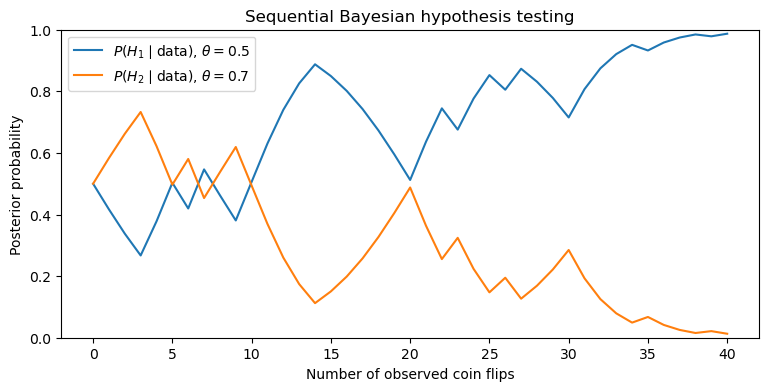

In [5]:

plt.figure(figsize=(9,4))

plt.plot(p_fair_history, label=r"$P(H_1\mid \mathrm{data})$, $\theta=0.5$")
plt.plot(p_biased_history, label=r"$P(H_2\mid \mathrm{data})$, $\theta=0.7$")

plt.xlabel("Number of observed coin flips")
plt.ylabel("Posterior probability")
plt.ylim(0,1)
plt.title("Sequential Bayesian hypothesis testing")
plt.legend()
plt.savefig('seq-bayesian-hypothesis.png',dpi=500)



The important point is that after every new observation,

$$
\boxed{
\text{posterior at step }k
\;\longrightarrow\;
\text{prior at step }k+1
}
$$

so the inference is updated sequentially as data arrive.



# Part 2: Inferring the probability of heads

Now suppose we do **not** restrict \(\theta\) to two possible values.

Instead,

$$
0\le \theta\le 1
$$

is unknown.

We place a probability distribution over \(\theta\).

A convenient prior for Bernoulli/binomial data is the Beta distribution,

$$
\theta\sim\operatorname{Beta}(\alpha,\beta).
$$

Its density is

$$
p(\theta)
\propto
\theta^{\alpha-1}(1-\theta)^{\beta-1}.
$$

We start with

$$
\alpha=1,\qquad \beta=1,
$$

which gives the uniform prior

$$
\theta\sim\operatorname{Beta}(1,1).
$$



If we observe one new coin flip \(X_i\),

- heads $X_i=1$ increases $\alpha$ by one,
- tails $X_i=0$ increases $\beta$ by one.

Therefore, after observing

$$
h=\text{number of heads},
\qquad
t=\text{number of tails},
$$

the posterior is

$$
\boxed{
\theta\mid \text{data}
\sim
\operatorname{Beta}(\alpha_0+h,\beta_0+t).
}
$$

For the uniform prior,

$$
\alpha_0=\beta_0=1.
$$


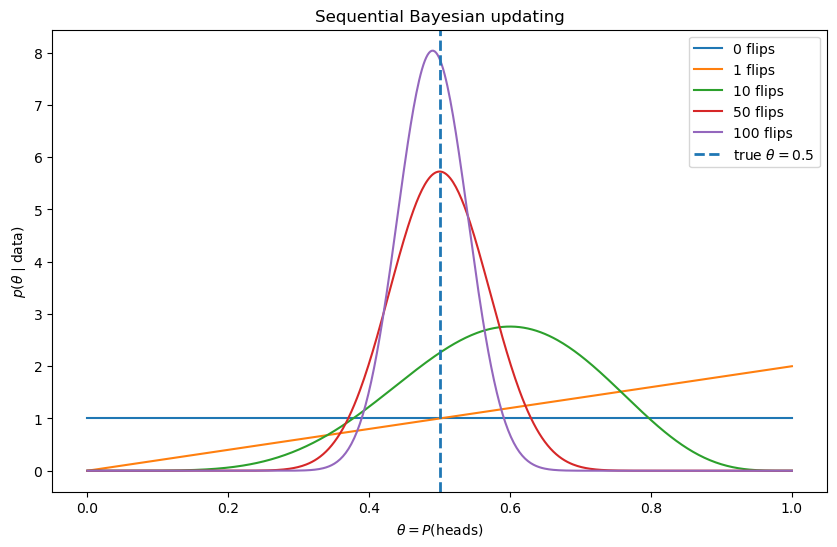

In [6]:
rng = np.random.default_rng(10)

theta_true = 0.5
n_flips = 100

x = rng.binomial(1, theta_true, size=n_flips)

alpha0 = 1
beta0 = 1

theta_grid = np.linspace(0,1,500)

# Selected snapshots
snapshots = [0, 1, 10,  50, 100]

plt.figure(figsize=(10,6))

for k in snapshots:
    heads = np.sum(x[:k])
    tails = k - heads

    alpha_post = alpha0 + heads
    beta_post = beta0 + tails

    posterior = beta.pdf(theta_grid, alpha_post, beta_post)

    plt.plot(
        theta_grid,
        posterior,
        label=f"{k} flips"
    )

plt.axvline(theta_true, linestyle="--", linewidth=2, label=r"true $\theta=0.5$")
plt.xlabel(r"$\theta=P(\mathrm{heads})$")
plt.ylabel(r"$p(\theta\mid \mathrm{data})$")
plt.title("Sequential Bayesian updating")
plt.legend()
plt.savefig('bayesian-update-coin.png',dpi=500)



As more observations are collected,

$$
p(\theta\mid x_1,\ldots,x_n)
$$

becomes increasingly concentrated near the value of \(\theta\) supported by the data.

This illustrates one of the main differences from maximum likelihood estimation:

$$
\boxed{
\text{MLE gives a point estimate }\hat\theta
}
$$

whereas Bayesian inference gives

$$
\boxed{
\text{a probability distribution over }\theta.
}
$$



## Posterior mean and posterior uncertainty

For

$$
\theta\mid \text{data}
\sim
\operatorname{Beta}(\alpha,\beta),
$$

the posterior mean is

$$
E[\theta\mid\text{data}]
=
\frac{\alpha}{\alpha+\beta},
$$

and the posterior variance is

$$
\operatorname{Var}(\theta\mid\text{data})
=
\frac{\alpha\beta}
{(\alpha+\beta)^2(\alpha+\beta+1)}.
$$

We can track both quantities after every new observation.


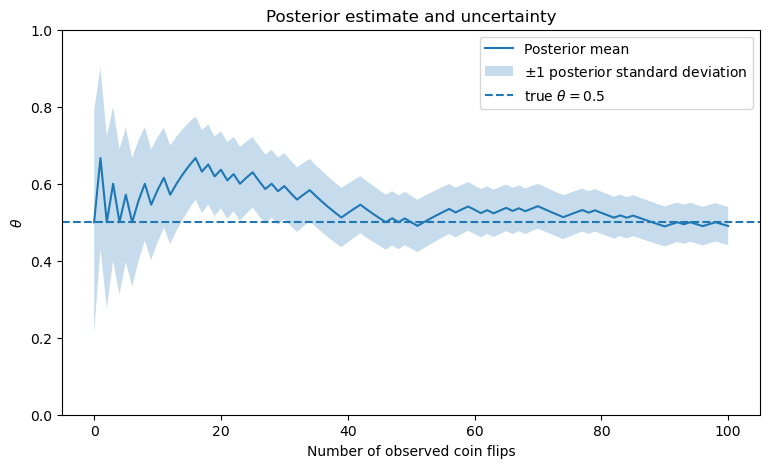

In [13]:

posterior_mean = []
posterior_std = []

for k in range(n_flips + 1):
    heads = np.sum(x[:k])
    tails = k - heads

    alpha_post = alpha0 + heads
    beta_post = beta0 + tails

    mean = alpha_post / (alpha_post + beta_post)

    var = (
        alpha_post * beta_post
        / (
            (alpha_post + beta_post)**2
            * (alpha_post + beta_post + 1)
        )
    )

    posterior_mean.append(mean)
    posterior_std.append(np.sqrt(var))

posterior_mean = np.array(posterior_mean)
posterior_std = np.array(posterior_std)

k = np.arange(n_flips + 1)

plt.figure(figsize=(9,5))

plt.plot(k, posterior_mean, label="Posterior mean")
plt.fill_between(
    k,
    posterior_mean - posterior_std,
    posterior_mean + posterior_std,
    alpha=0.25,
    label=r"$\pm 1$ posterior standard deviation"
)

plt.axhline(theta_true, linestyle="--", label=r"true $\theta=0.5$")

plt.xlabel("Number of observed coin flips")
plt.ylabel(r"$\theta$")
plt.ylim(0,1)
plt.title("Posterior estimate and uncertainty")
plt.legend()
plt.show()



# Part 3: Why the prior matters for small datasets

Suppose we observe

$$
H,H,H.
$$

The maximum likelihood estimate is

$$
\hat\theta_{\rm MLE}=1.
$$

Now compare that with Bayesian inference using a prior centered around a fair coin.

For example,

$$
\theta\sim\operatorname{Beta}(10,10).
$$

After observing three heads,

$$
\theta\mid H,H,H
\sim
\operatorname{Beta}(13,10).
$$

The posterior mean is therefore

$$
E[\theta\mid H,H,H]
=
\frac{13}{23}
\approx 0.565.
$$

So three heads move our belief toward larger \(\theta\), but they do not force us to conclude that

$$
\theta=1.
$$


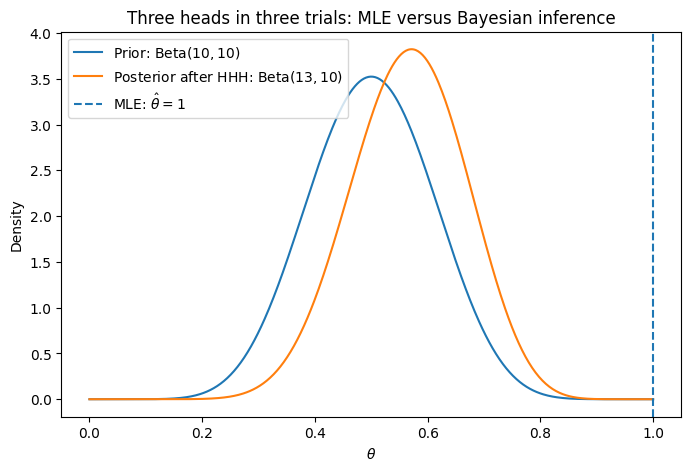

MLE = 1.0
Posterior mean = 0.5652173913043478


In [15]:
theta_grid = np.linspace(0,1,500)

# informative prior
alpha_prior = 10
beta_prior = 10

# observe H,H,H
heads = 3
tails = 0

alpha_post = alpha_prior + heads
beta_post = beta_prior + tails

prior_pdf = beta.pdf(theta_grid, alpha_prior, beta_prior)
posterior_pdf = beta.pdf(theta_grid, alpha_post, beta_post)

plt.figure(figsize=(8,5))

plt.plot(theta_grid, prior_pdf, label=r"Prior: Beta$(10,10)$")
plt.plot(theta_grid, posterior_pdf, label=r"Posterior after HHH: Beta$(13,10)$")
plt.axvline(1.0, linestyle="--", label=r"MLE: $\hat{\theta}=1$")

plt.xlabel(r"$\theta$")
plt.ylabel("Density")
plt.title("Three heads in three trials: MLE versus Bayesian inference")
plt.legend()
plt.show()

print("MLE =", 1.0)
print("Posterior mean =", alpha_post/(alpha_post+beta_post))



## Main idea

Bayesian inference combines

$$
\boxed{
\text{prior information}
+
\text{new data}
}
$$

through Bayes' rule:

$$
p(\theta\mid x)
=
\frac{
p(x\mid\theta)p(\theta)
}{
p(x)
}.
$$

Sequentially,

$$
\boxed{
p_k(\theta)
\;\longrightarrow\;
p(\theta\mid x_{k+1})
\;\longrightarrow\;
p_{k+1}(\theta).
}
$$

With more data, the likelihood increasingly dominates the prior and the posterior becomes more concentrated.
